In [6]:
from google.colab import files
uploaded = files.upload()

Saving no_label.csv to no_label.csv


In [7]:

import pandas as pd
import os

filename = next(iter(uploaded.keys()))

df = pd.read_csv(filename)

print("File loaded:", filename)
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


File loaded: no_label.csv
Dataset shape: (500, 2)
Column names: ['English', 'Hindi']


,English,Hindi
0,The average geological temperature of the eart...,1995 से 2004 के दौरान औसत धरातलीय तापमान 1940 ...
1,Dhrudharashtra and Ghandhari 's eldest among t...,धृतराष्ट्र एवं गांधारी के १०० पुत्रों में सबसे...
2,In this way a major part of the desert in Raja...,इस प्रकार राजस्थान के रेगिस्तान का एक बड़ा भाग...
3,The power of the President to proclaim Ordinan...,राष्ट्रपति की अध्यादेश जारी करने की शक्ति पे न...
4,More than 1000 elephants were used during the ...,1000 से अधिक हाथी निर्माण के दौरान यातायात हेत...


In [8]:

print(df.info())
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   English  500 non-null    object
 1   Hindi    500 non-null    object
dtypes: object(2)
memory usage: 7.9+ KB
None
English    0
Hindi      0
dtype: int64


In [9]:

print(df.head(10).to_string(index=False))


                                                                                             English                                                                                                  Hindi
The average geological temperature of the earth from 1995-2004 is different than that of 1940-1980 .                    1995 से 2004 के दौरान औसत धरातलीय तापमान 1940 से 1980 तक के औसत तापमान से भिन्‍न है
                                       Dhrudharashtra and Ghandhari 's eldest among their 200 sons .                                                  धृतराष्ट्र एवं गांधारी के १०० पुत्रों में सबसे बड़े ।
    In this way a major part of the desert in Rajasthan would become a harvesting and fertile land .                      इस प्रकार राजस्थान के रेगिस्तान का एक बड़ा भाग शस्य श्यामला भूमि में बदल जायेगा ।
                                    The power of the President to proclaim Ordinance is subject to :                                                  राष्ट्रपति की अध्यादेश जारी करने क

In [10]:

df = df.rename(columns={
    "English": "english",
    "Hindi": "hinglish"
})

df = df.dropna()
df = df.drop_duplicates()

df["english"] = df["english"].astype(str).str.strip()
df["hinglish"] = df["hinglish"].astype(str).str.strip()

print("Total sentence pairs:", len(df))
display(df.head())


Total sentence pairs: 500


,english,hinglish
0,The average geological temperature of the eart...,1995 से 2004 के दौरान औसत धरातलीय तापमान 1940 ...
1,Dhrudharashtra and Ghandhari 's eldest among t...,धृतराष्ट्र एवं गांधारी के १०० पुत्रों में सबसे...
2,In this way a major part of the desert in Raja...,इस प्रकार राजस्थान के रेगिस्तान का एक बड़ा भाग...
3,The power of the President to proclaim Ordinan...,राष्ट्रपति की अध्यादेश जारी करने की शक्ति पे न...
4,More than 1000 elephants were used during the ...,1000 से अधिक हाथी निर्माण के दौरान यातायात हेत...


In [11]:

!pip install -q indic-transliteration


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.9/162.9 kB 3.5 MB/s eta 0:00:00


In [12]:

import pandas as pd
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate

df = pd.read_csv("/content/no_label.csv")

df["hinglish"] = df["Hindi"].astype(str).apply(
    lambda x: transliterate(x, sanscript.DEVANAGARI, sanscript.ITRANS)
)

df["english"] = df["English"].astype(str)

df = df[["english", "hinglish"]].dropna()
df = df.drop_duplicates().reset_index(drop=True)

print(df.head(10).to_string(index=False))
print("Total sentence pairs:", len(df))

df.to_csv(
    "/content/english_hinglish.csv",
    index=False
)


                                                                                             english                                                                                                       hinglish
The average geological temperature of the earth from 1995-2004 is different than that of 1940-1980 .       1995 se 2004 ke daurAna ausata dharAtalIya tApamAna 1940 se 1980 taka ke ausata tApamAna se bhin{}na hai
                                       Dhrudharashtra and Ghandhari 's eldest among their 200 sons .                                                  dhRRitarAShTra evaM gAMdhArI ke 100 putroM meM sabase ba.De |
    In this way a major part of the desert in Rajasthan would become a harvesting and fertile land .               isa prakAra rAjasthAna ke registAna kA eka ba.DA bhAga shasya shyAmalA bhUmi meM badala jAyegA |
                                    The power of the President to proclaim Ordinance is subject to :                                                  rA

In [13]:

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Training sentence pairs:", len(train_df))
print("Testing sentence pairs:", len(test_df))


Training sentence pairs: 400
Testing sentence pairs: 100


In [14]:

!pip install -q tensorflow pandas scikit-learn nltk indic-transliteration matplotlib


In [15]:

from google.colab import files

uploaded = files.upload()


Saving no_label.csv to no_label (1).csv


Total sentence pairs: 500
                                             english  \
0  the average geological temperature of the eart...   
1  dhrudharashtra and ghandhari 's eldest among t...   
2  in this way a major part of the desert in raja...   
3  the power of the president to proclaim ordinan...   
4  more than 1000 elephants were used during the ...   

                                            hinglish  
0  1995 se 2004 ke daurana ausata dharataliya tap...  
1  dhrritarashtra evam gamdhari ke 100 putrom mem...  
2  isa prakara rajasthana ke registana ka eka ba....  
3  rashtrapati ki adhyadesha jari karane ki shakt...  
4  1000 se adhika hathi nirmana ke daurana yataya...  


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 19, 64)    │    110,400 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 19)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 20, 64)    │    119,040 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 128),     │     98,816 │ embedding[0][0],  │
│                     │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 20, 128), │     98,816 │ embedding_1[0][0… │
│                     │ (None, 128),      │            │ encoder_lstm[0][… │
│                     │ (None, 128)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 20, 1860)  │    239,940 │ decoder_lstm[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 667,012 (2.54 MB)

 Trainable params: 667,012 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 122ms/step - loss: 6.7938 - sparse_categorical_accuracy: 0.0727 - val_loss: 6.1019 - val_sparse_categorical_accuracy: 0.0701
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step - loss: 5.8273 - sparse_categorical_accuracy: 0.0875 - val_loss: 6.2171 - val_sparse_categorical_accuracy: 0.0863
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - loss: 5.6109 - sparse_categorical_accuracy: 0.0998 - val_loss: 6.2838 - val_sparse_categorical_accuracy: 0.0919
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 5.4939 - sparse_categorical_accuracy: 0.1032 - val_loss: 6.2657 - val_sparse_categorical_accuracy: 0.0912
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 5.3854 - sparse_categorical_accuracy: 0.1036 - val_loss: 6.2222 - val_sparse_categorical_accuracy: 0.0933
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - loss: 5.2808 - sparse_categorical_accuracy: 0.1099 - val_loss: 6.1946 - val_sparse_categorical_accuracy: 0.1073
Traini

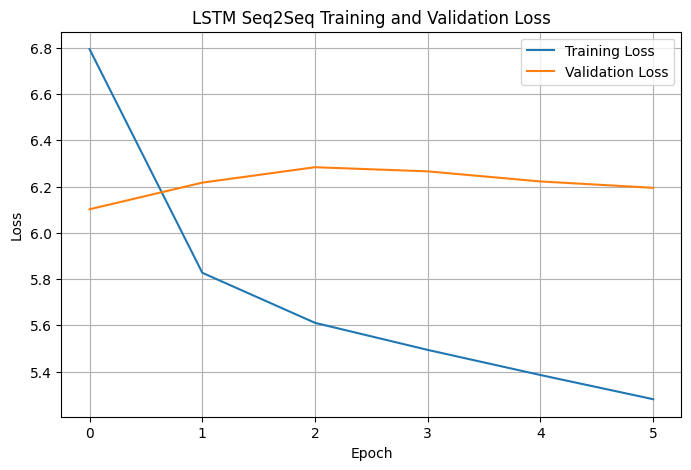

Test BLEU score: 0.0000

Five example translations:
English: Good morning
Hinglish: 
----------------------------------------
English: Please help me
Hinglish: 
----------------------------------------
English: I am going to school
Hinglish: 
----------------------------------------
English: Where is the bus stop?
Hinglish: 
----------------------------------------
English: I want to learn English
Hinglish: 
----------------------------------------


In [16]:

import os
import re
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

df = pd.read_csv("/content/no_label.csv")
df = df[["English", "Hindi"]].dropna().drop_duplicates()

def to_roman(text):
    return transliterate(str(text), sanscript.DEVANAGARI, sanscript.ITRANS)

def clean_text(text):
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

df["english"] = df["English"].apply(clean_text)
df["hinglish"] = df["Hindi"].apply(to_roman).apply(clean_text)

df = df[
    (df["english"] != "") & (df["hinglish"] != "")
].reset_index(drop=True)

print("Total sentence pairs:", len(df))
print(df[["english", "hinglish"]].head())

df[["english", "hinglish"]].to_csv(
    "/content/english_hinglish.csv", index=False
)

train_df, test_df = train_test_split(
    df[["english", "hinglish"]],
    test_size=0.2,
    random_state=SEED
)
train_target = train_df["hinglish"].apply(
    lambda s: "<start> " + s + " <end>"
).tolist()

test_target = test_df["hinglish"].apply(
    lambda s: "<start> " + s + " <end>"
).tolist()

eng_tokenizer = Tokenizer(
    filters="", lower=True, oov_token="<unk>"
)
hin_tokenizer = Tokenizer(
    filters="", lower=True, oov_token="<unk>"
)

eng_tokenizer.fit_on_texts(train_df["english"].tolist())
hin_tokenizer.fit_on_texts(train_target)

eng_vocab_size = len(eng_tokenizer.word_index) + 1
hin_vocab_size = len(hin_tokenizer.word_index) + 1

start_id = hin_tokenizer.word_index["<start>"]
end_id = hin_tokenizer.word_index["<end>"]

X_train_seq = eng_tokenizer.texts_to_sequences(
    train_df["english"].tolist()
)
Y_train_seq = hin_tokenizer.texts_to_sequences(train_target)

X_test_seq = eng_tokenizer.texts_to_sequences(
    test_df["english"].tolist()
)
Y_test_seq = hin_tokenizer.texts_to_sequences(test_target)

max_eng_len = max(map(len, X_train_seq))
max_hin_len = max(map(len, Y_train_seq))

X_train = pad_sequences(
    X_train_seq, maxlen=max_eng_len, padding="post"
)
Y_train = pad_sequences(
    Y_train_seq, maxlen=max_hin_len, padding="post"
)

X_test = pad_sequences(
    X_test_seq, maxlen=max_eng_len, padding="post"
)
Y_test = pad_sequences(
    Y_test_seq, maxlen=max_hin_len, padding="post"
)

decoder_train = Y_train[:, :-1]
decoder_target = Y_train[:, 1:]

decoder_test = Y_test[:, :-1]
decoder_test_target = Y_test[:, 1:]

train_weights = (decoder_target != 0).astype("float32")
test_weights = (decoder_test_target != 0).astype("float32")

embedding_dim = 64
latent_dim = 128

encoder_inputs = Input(shape=(max_eng_len,), name="encoder_input")
encoder_embedding = Embedding(
    eng_vocab_size, embedding_dim, mask_zero=True
)
encoder_lstm = LSTM(
    latent_dim, return_state=True, name="encoder_lstm"
)

encoder_embedded = encoder_embedding(encoder_inputs)
_, state_h, state_c = encoder_lstm(encoder_embedded)
encoder_states = [state_h, state_c]

decoder_inputs = Input(
    shape=(max_hin_len - 1,), name="decoder_input"
)
decoder_embedding = Embedding(
    hin_vocab_size, embedding_dim, mask_zero=True
)
decoder_lstm = LSTM(
    latent_dim, return_sequences=True,
    return_state=True, name="decoder_lstm"
)
decoder_dense = Dense(hin_vocab_size, activation="softmax")

decoder_embedded = decoder_embedding(decoder_inputs)
decoder_outputs, _, _ = decoder_lstm(
    decoder_embedded, initial_state=encoder_states
)
decoder_outputs = decoder_dense(decoder_outputs)

model = Model(
    [encoder_inputs, decoder_inputs], decoder_outputs
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["sparse_categorical_accuracy"]
)

model.summary()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    [X_train, decoder_train],
    decoder_target,
    sample_weight=train_weights,
    validation_data=(
        [X_test, decoder_test],
        decoder_test_target,
        test_weights
    ),
    epochs=30,
    batch_size=16,
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

model.save("/content/english_hinglish_lstm.keras")
print("Training completed!")

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Seq2Seq Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()
encoder_model = Model(encoder_inputs, encoder_states)

state_h_input = Input(shape=(latent_dim,))
state_c_input = Input(shape=(latent_dim,))
token_input = Input(shape=(1,))

embedded_token = decoder_embedding(token_input)

out, next_h, next_c = decoder_lstm(
    embedded_token,
    initial_state=[state_h_input, state_c_input]
)
out = decoder_dense(out)

decoder_model = Model(
    [token_input, state_h_input, state_c_input],
    [out, next_h, next_c]
)

id_to_word = {
    idx: word for word, idx in hin_tokenizer.word_index.items()
}

def translate(sentence):
    seq = eng_tokenizer.texts_to_sequences([clean_text(sentence)])
    seq = pad_sequences(
        seq, maxlen=max_eng_len, padding="post"
    )

    states = encoder_model.predict(seq, verbose=0)
    token = np.array([[start_id]])
    result = []

    for _ in range(max_hin_len - 1):
        output, h, c = decoder_model.predict(
            [token, states[0], states[1]], verbose=0
        )

        predicted_id = int(np.argmax(output[0, -1, :]))

        if predicted_id in (0, end_id):
            break

        word = id_to_word.get(predicted_id, "<unk>")
        if word != "<start>":
            result.append(word)

        token = np.array([[predicted_id]])
        states = [h, c]

    return " ".join(result)

references = []
hypotheses = []
smooth = SmoothingFunction().method1

for _, row in test_df.iterrows():
    actual = row["hinglish"].split()
    predicted = translate(row["english"]).split()

    references.append([actual])
    hypotheses.append(predicted)

bleu = corpus_bleu(
    references, hypotheses,
    smoothing_function=smooth
)

print(f"Test BLEU score: {bleu:.4f}")

unseen_sentences = [
    "Good morning",
    "Please help me",
    "I am going to school",
    "Where is the bus stop?",
    "I want to learn English"
]

print("\nFive example translations:")
for sentence in unseen_sentences:
    print("English:", sentence)
    print("Hinglish:", translate(sentence))
    print("-" * 40)
